# Puzzle World 



1. **Tahap 1 — Generator**: citra masukan → 1 bingkai (`frame.png`, bagian tengah transparan) + M×M potongan (`piece_*.png`).
2. **Tahap 2 — Solver**: hanya dari 1 bingkai + N potongan, potongan disusun kembali ke dalam lubang bingkai. Bingkai menjadi acuan: potongan yang menempel bingkai dipasang lebih dulu (Tahap 1 solver), baru bagian dalam diisi mengikuti tetangga yang sudah terpasang (Tahap 2 solver).




In [1]:
import json
import random
import time
from pathlib import Path

import cv2
import numpy as np

BORDER = 0.06         # lebar bingkai (rasio terhadap sisi terpendek), tetap
THRESHOLD = 90.0      # ambang skor "masuk/ragu" (%), tetap

In [2]:
import matplotlib.pyplot as plt
%matplotlib inline

# Warna grafik (palet kategorikal tervalidasi: biru, oranye, aqua)
C_BLUE, C_ORANGE, C_AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

## 1. Fungsi tampilan



In [3]:
def show(ax, img_bgr, title=""):
    ax.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    ax.set_title(title, fontsize=10, color=INK)
    ax.axis("off")


def frame_on_checker(frame_bgra):
    """Bingkai BGRA di atas pola kotak-kotak abu-abu supaya lubang transparan terlihat."""
    h, w = frame_bgra.shape[:2]
    yy, xx = np.mgrid[0:h, 0:w]
    chk = ((((yy // 12) + (xx // 12)) % 2) * 40 + 170).astype(np.float32)
    bg = np.dstack([chk, chk, chk])
    a = frame_bgra[..., 3:4].astype(np.float32) / 255.0
    return (frame_bgra[..., :3] * a + bg * (1 - a)).astype(np.uint8)


def contact_sheet(pieces, thumb=140):
    """Semua potongan dalam satu lembar, berlabel nomor berkas."""
    n = len(pieces)
    cols = int(np.ceil(np.sqrt(n)))
    rows = int(np.ceil(n / cols))
    ph, pw = pieces[0].shape[:2]
    s = min(thumb / max(ph, pw), 1.0)
    tw, th = max(1, int(pw * s)), max(1, int(ph * s))
    pad, lab = 8, 16
    cw_, ch_ = tw + pad, th + pad + lab
    sheet = np.full((rows * ch_ + pad, cols * cw_ + pad, 3), 30, np.uint8)
    for i, p in enumerate(pieces):
        r, c = divmod(i, cols)
        x, y = pad + c * cw_, pad + r * ch_
        sheet[y + lab:y + lab + th, x:x + tw] = cv2.resize(p, (tw, th), interpolation=cv2.INTER_AREA)
        cv2.putText(sheet, f"{i:03d}", (x, y + 12), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (220, 220, 220), 1, cv2.LINE_AA)
    return sheet


def report(res, thr=THRESHOLD):
    """Ringkasan kecocokan per tahap solver (skor % dari selisih piksel tepi)."""
    for phase, label in ((1, "Tahap 1 (cocokkan ke bingkai)"), (2, "Tahap 2 (isi bagian dalam)")):
        sc = [percent(s[4]) for s in res["steps"] if s[0] == phase]
        if sc:
            print(f"  {label}: {len(sc)} potongan, rata-rata {np.mean(sc):.1f}%, min {np.min(sc):.1f}%, "
                  f"ragu (<{thr:.0f}%): {sum(x < thr for x in sc)}")

## 2. Tahap 1 — Generator

**Alur:** baca citra (RGB atau grayscale; grayscale diduplikasi ke 3 kanal) → hitung tata letak (`plan_layout`: lebar bingkai `b` tetap 6% sisi terpendek, ukuran sel, sisa piksel dibuang supaya habis dibagi M, rasio tetap) → **bingkai dibuat dulu**: citra utuh dengan bagian dalam dijadikan transparan → bagian dalam **dipotong** M×M → urutan potongan diacak.

Bingkai tetap berisi piksel asli di tepinya, itulah yang dipakai solver sebagai acuan. `metadata.json` hanya kunci jawaban untuk mengukur akurasi dan **tidak dibaca solver**.

In [4]:
def load_image(src):
    """Baca gambar (path atau array BGR) sebagai BGR 3 kanal.
    Grayscale otomatis diduplikasi ke 3 kanal."""
    if isinstance(src, np.ndarray):
        img = src.copy()
        if img.ndim == 2:
            img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    else:
        img = cv2.imread(str(src), cv2.IMREAD_COLOR)
        if img is None:
            raise FileNotFoundError(f"Gambar tidak dapat dibaca: {src}")
    return img


def plan_layout(h, w, m, border):
    """Lebar bingkai (b) dan ukuran sel (ch x cw) agar bagian dalam habis dibagi M."""
    b = int(round(border * min(h, w))) if 0 < border < 1 else int(border)
    b = max(b, 3)                      # solver memakai 3 lapis piksel bingkai di tiap sisi
    ch, cw = (h - 2 * b) // m, (w - 2 * b) // m
    if ch < 8 or cw < 8:
        raise ValueError("Gambar terlalu kecil untuk M / lebar bingkai ini.")
    return b, ch, cw

In [5]:
def generate(src, m, out_dir, write_meta=True, verbose=True):
    """Tahap 1: buat 1 bingkai (frame.png) + M*M potongan (piece_*.png) di out_dir.
    Mengembalikan metadata (kunci jawaban) berisi posisi asli tiap potongan."""
    rng = random.Random()                       # untuk pengacakan urutan potongan
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    for f in list(out_dir.glob("piece_*.png")) + [out_dir / "frame.png", out_dir / "metadata.json"]:
        f.unlink(missing_ok=True)

    img = load_image(src)
    b, ch, cw = plan_layout(*img.shape[:2], m, BORDER)
    inner_h, inner_w = m * ch, m * cw
    img = img[: inner_h + 2 * b, : inner_w + 2 * b].copy()       # buang sisa < M piksel, rasio praktis tetap
    H, W = img.shape[:2]

    # --- 1. Bingkai: citra utuh, bagian dalam (lubang) transparan (alpha = 0) ---
    frame = np.dstack([img, np.full((H, W), 255, np.uint8)])
    frame[b:b + inner_h, b:b + inner_w] = 0
    cv2.imwrite(str(out_dir / "frame.png"), frame)

    # --- 2. Potongan: bagian dalam dipotong grid M x M ---
    inner = img[b:b + inner_h, b:b + inner_w]
    pieces = []
    for r in range(m):
        for c in range(m):
            p = inner[r * ch:(r + 1) * ch, c * cw:(c + 1) * cw].copy()
            pieces.append((r, c, p))
    rng.shuffle(pieces)                                          # nama file tidak membocorkan posisi

    meta = {"m": m, "n_pieces": m * m, "image_size": [W, H], "border": b,
            "hole": {"x": b, "y": b, "w": inner_w, "h": inner_h}, "cell_size": [cw, ch],
            "pieces": []}
    for idx, (r, c, p) in enumerate(pieces):
        name = f"piece_{idx:03d}.png"
        cv2.imwrite(str(out_dir / name), p)
        meta["pieces"].append({"file": name, "row": r, "col": c})
    if write_meta:
        (out_dir / "metadata.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
    if verbose:
        print(f"Generator: 1 bingkai + {m * m} potongan -> '{out_dir}' "
              f"(gambar {W}x{H}, bingkai {b}px, sel {cw}x{ch})")
    return meta

### Demo generator
Contoh: gambar milik Anda (ubah `DEMO_IMAGE`), M = 4. Kiri: bingkai (kotak-kotak abu-abu = lubang transparan). Kanan: potongan dalam urutan berkas (sudah diacak).

Generator: 1 bingkai + 16 potongan -> 'puzzle_out' (gambar 1196x1600, bingkai 72px, sel 263x364)


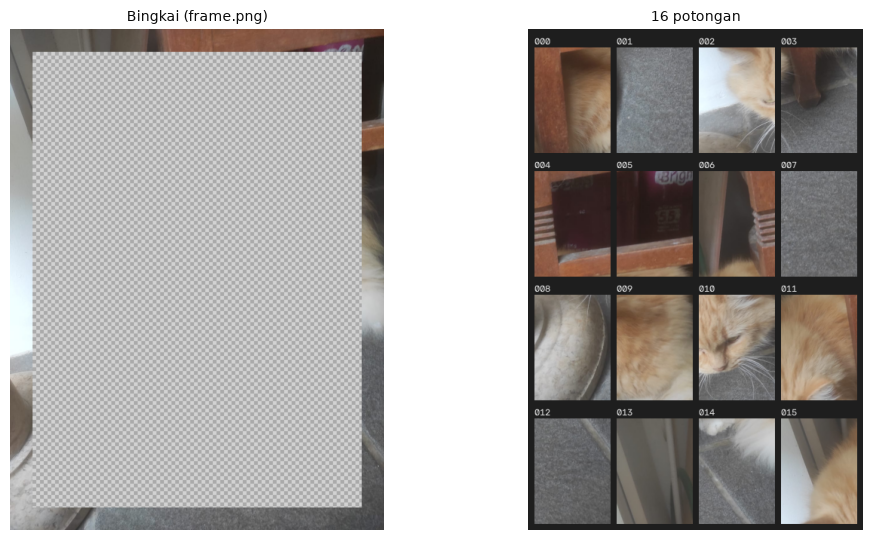

In [6]:
OUT = Path("puzzle_out")
DEMO_IMAGE = "kavka.jpg"        # ganti dengan path gambar Anda
img = load_image(DEMO_IMAGE)
meta = generate(img, m=4, out_dir=OUT)

frame_bgra = cv2.imread(str(OUT / "frame.png"), cv2.IMREAD_UNCHANGED)
pieces = [cv2.imread(str(OUT / p["file"])) for p in meta["pieces"]]
fig, ax = plt.subplots(1, 2, figsize=(11, 5.5))
show(ax[0], frame_on_checker(frame_bgra), "Bingkai (frame.png)")
show(ax[1], contact_sheet(pieces), f"{meta['n_pieces']} potongan")
plt.tight_layout(); plt.show()

## 3. Tahap 2 — Solver

Input solver hanya folder berisi `frame.png` dan `piece_*.png`. Langkah kerjanya:

1. **Muat bingkai**, cari lubang transparan (alpha = 0) → posisi dan ukuran area susunan. Cek ukuran lubang = M × ukuran potongan.
2. **Siapkan potongan** (satu varian per potongan).
3. **Hitung biaya kecocokan tepi** antara semua pasangan sisi, dan antara sisi potongan dengan piksel bingkai di sebelahnya. Biaya adalah jumlah berbobot dua komponen:
   - `plain`: rata-rata |tepi A − tepi B| (pengurangan citra)
   - `grad`: prediksi gradien. Tepi A diekstrapolasi satu piksel (`2·tepi − dalam`) lalu dibandingkan dengan tepi B, dan sebaliknya (beda hingga)
4. **Penempatan best-first per tahap**: Tahap 1 mengisi cincin (slot yang menempel bingkai), Tahap 2 mengisi bagian dalam. Di tiap langkah dipilih (slot, potongan) dengan biaya terendah yang paling jauh lebih baik daripada kandidat lain.
5. **Skor** `(1 − selisih/255) × 100%`; di bawah ambang (90%) ditandai "ragu".

Bingkai menetapkan posisi absolut tiap potongan.

In [7]:
def load_frame(folder):
    """Baca frame.png (BGRA) -> (bingkai float32 BGR, (x0, y0, w, h) lubang transparan)."""
    fr = cv2.imread(str(Path(folder) / "frame.png"), cv2.IMREAD_UNCHANGED)
    if fr is None or fr.ndim != 3 or fr.shape[2] != 4:
        raise FileNotFoundError("frame.png (RGBA, lubang transparan) tidak ditemukan.")
    ys, xs = np.where(fr[..., 3] == 0)
    if len(ys) == 0:
        raise ValueError("Bingkai tidak punya lubang transparan.")
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    return fr[..., :3].astype(np.float32), (int(x0), int(y0), int(x1 - x0), int(y1 - y0))


def load_pieces(folder):
    files = sorted(Path(folder).glob("piece_*.png"))
    if not files:
        raise FileNotFoundError(f"Tidak ada piece_*.png di {folder}")
    pieces = [cv2.imread(str(f), cv2.IMREAD_COLOR) for f in files]
    if any(p.shape != pieces[0].shape for p in pieces):
        raise ValueError("Ukuran semua potongan harus sama.")
    return [f.name for f in files], pieces


def build_variants(pieces):
    """Daftar varian (indeks_potongan, 0, array float32): satu varian per potongan (tanpa rotasi)."""
    return [(i, 0, p.astype(np.float32)) for i, p in enumerate(pieces)]

### Biaya kecocokan tepi

In [8]:
DEPTH = 3     # jumlah lapis piksel yang dipakai dari tiap sisi


def stack_sides(stack, w=DEPTH):
    """stack (V,H,W,3) -> dict sisi -> (V, w, L, 3); indeks 0 = piksel terluar, 1 = di sebelah dalamnya, dst."""
    return {
        "T": np.stack([stack[:, d] for d in range(w)], 1),
        "B": np.stack([stack[:, -1 - d] for d in range(w)], 1),
        "L": np.stack([stack[:, :, d] for d in range(w)], 1),
        "R": np.stack([stack[:, :, -1 - d] for d in range(w)], 1),
    }


def edge_costs(a, B, W):
    """Ketidakcocokan satu sisi `a` (w,L,3) terhadap banyak sisi B (V,w,L,3), skala piksel 0-255.
    W = bobot tiap komponen:
      plain : |tepi A - tepi B|                                (pengurangan citra)
      grad  : prediksi gradien 2*tepi - dalam (beda hingga)    (turunan sederhana)"""
    a0, a1, B0, B1 = a[0], a[1], B[:, 0], B[:, 1]
    cost = np.zeros(len(B), np.float32)
    if W.get("plain"):
        cost += W["plain"] * np.abs(a0[None] - B0).mean(axis=(1, 2))
    if W.get("grad"):
        pa, pb = 2 * a0 - a1, 2 * B0 - B1
        g = 0.5 * (np.abs(pa[None] - B0).mean(axis=(1, 2)) + np.abs(pb - a0[None]).mean(axis=(1, 2)))
        cost += W["grad"] * g
    return cost


def piece_matrix(sides, orient, W):
    """D[i, j]: ketidakcocokan jika varian i di KIRI ('h') / ATAS ('v') varian j."""
    a_side, b_side = ("R", "L") if orient == "h" else ("B", "T")
    A, B = sides[a_side], sides[b_side]
    V = len(A)
    D = np.empty((V, V), np.float32)
    for i in range(V):
        D[i] = edge_costs(A[i], B, W)
    return D


def frame_costs(frame, hole, m, sides, W, w=DEPTH):
    """Untuk tiap slot di cincin: vektor biaya (panjang V) antara sisi potongan yang menempel
    bingkai dan piksel bingkai di sebelahnya. Slot sudut punya 2 vektor."""
    x0, y0, hw, hh = hole
    cw, ch = hw // m, hh // m
    yb, xr = y0 + hh, x0 + hw

    terms = {}
    for r in range(m):
        for c in range(m):
            xs, xe, ys, ye = x0 + c * cw, x0 + (c + 1) * cw, y0 + r * ch, y0 + (r + 1) * ch
            t = []
            if r == 0:
                d = np.stack([frame[y0 - 1 - k, xs:xe] for k in range(w)])
                t.append(edge_costs(d, sides["T"], W))
            if r == m - 1:
                d = np.stack([frame[yb + k, xs:xe] for k in range(w)])
                t.append(edge_costs(d, sides["B"], W))
            if c == 0:
                d = np.stack([frame[ys:ye, x0 - 1 - k] for k in range(w)])
                t.append(edge_costs(d, sides["L"], W))
            if c == m - 1:
                d = np.stack([frame[ys:ye, xr + k] for k in range(w)])
                t.append(edge_costs(d, sides["R"], W))
            if t:
                terms[(r, c)] = t
    return terms


def percent(d):
    """Selisih piksel (0-255) -> kecocokan 0-100%."""
    return float(max(0.0, 1.0 - d / 255.0) * 100.0)

In [9]:
def solve(Dh, Dv, piece_of, m, fterms):
    """Penyusunan bertahap, best-first. Tahap 1: cincin (menempel bingkai). Tahap 2: bagian dalam.
    Di tiap langkah dipilih (slot, varian) yang biayanya terendah dan paling jauh lebih baik dari kandidat lain."""
    V, n = len(piece_of), m * m
    placed = -np.ones((m, m), int)
    used = np.zeros(n, bool)
    steps = []

    def slot_cost(r, c):
        total, cnt = np.zeros(V, np.float32), 0
        for t in fterms.get((r, c), []):
            total += t
            cnt += 1
        if c > 0 and placed[r, c - 1] >= 0:
            total += Dh[placed[r, c - 1]]; cnt += 1
        if c < m - 1 and placed[r, c + 1] >= 0:
            total += Dh[:, placed[r, c + 1]]; cnt += 1
        if r > 0 and placed[r - 1, c] >= 0:
            total += Dv[placed[r - 1, c]]; cnt += 1
        if r < m - 1 and placed[r + 1, c] >= 0:
            total += Dv[:, placed[r + 1, c]]; cnt += 1
        return total, cnt

    ring = [(r, c) for r in range(m) for c in range(m) if r in (0, m - 1) or c in (0, m - 1)]
    inner = [(r, c) for r in range(m) for c in range(m) if (r, c) not in set(ring)]
    for phase, slots in ((1, ring), (2, inner)):
        remaining = list(slots)
        while remaining:
            best = None
            for (r, c) in remaining:
                total, cnt = slot_cost(r, c)
                if cnt == 0:
                    continue
                cost = total / cnt
                cost[used[piece_of]] = np.inf
                j = int(np.argmin(cost))
                b = float(cost[j])
                if not np.isfinite(b):
                    continue
                c2 = cost.copy()
                c2[piece_of == piece_of[j]] = np.inf
                s = float(c2.min())
                conf = (b + 1.0) / (s + 1.0) if np.isfinite(s) else 0.0
                if best is None or (conf, b) < best[0]:
                    best = ((conf, b), (r, c), j, b)
            if best is None:
                raise RuntimeError("Tidak ada slot yang bisa diisi.")
            _, (r, c), j, b = best
            placed[r, c] = j
            used[piece_of[j]] = True
            remaining.remove((r, c))
            steps.append((phase, r, c, j, b))
    return placed, steps

### Solver lengkap
Solver memakai satu konfigurasi dasar: biaya `plain` dan `grad` berbobot sama (`WEIGHTS`).

In [10]:
WEIGHTS = {"plain": .5, "grad": .5}      # bobot komponen biaya


def solve_folder(folder):
    """Tahap 2: input = frame.png + piece_*.png di `folder`. Keluaran: hasil susunan + langkah-langkahnya."""
    frame, hole = load_frame(folder)
    names, pieces = load_pieces(folder)
    n = len(pieces)
    m = int(round(n ** 0.5))
    if m * m != n:
        raise ValueError(f"Jumlah potongan ({n}) bukan kuadrat sempurna (M x M).")
    ph, pw = pieces[0].shape[:2]
    if (hole[2], hole[3]) != (m * pw, m * ph):
        raise ValueError("Ukuran lubang bingkai tidak sama dengan M x ukuran potongan.")

    variants = build_variants(pieces)
    piece_of = np.array([v[0] for v in variants])
    stack = np.stack([v[2] for v in variants])
    sides = stack_sides(stack)
    Dh = piece_matrix(sides, "h", WEIGHTS)
    Dv = piece_matrix(sides, "v", WEIGHTS)
    same = piece_of[:, None] == piece_of[None, :]
    Dh[same] = np.inf
    Dv[same] = np.inf
    fterms = frame_costs(frame, hole, m, sides, WEIGHTS)
    placed, steps = solve(Dh, Dv, piece_of, m, fterms)
    return {"m": m, "hole": hole, "frame": frame, "placed": placed, "steps": steps,
            "variants": variants, "names": names}


def render(res):
    """Tempelkan potongan hasil susunan ke lubang bingkai -> gambar BGR utuh."""
    x0, y0, hw, hh = res["hole"]
    m = res["m"]
    cw, ch = hw // m, hh // m
    out = np.clip(res["frame"], 0, 255).astype(np.uint8).copy()
    for r in range(m):
        for c in range(m):
            out[y0 + r * ch:y0 + (r + 1) * ch, x0 + c * cw:x0 + (c + 1) * cw] = \
                np.clip(res["variants"][res["placed"][r, c]][2], 0, 255).astype(np.uint8)
    return out


def evaluate(res, meta):
    """Akurasi posisi terhadap kunci jawaban: bagian potongan yang menempati (baris, kolom) aslinya (0..1)."""
    truth = {p["file"]: (p["row"], p["col"]) for p in meta["pieces"]}
    m = res["m"]
    ok = 0
    for r in range(m):
        for c in range(m):
            i, _, _ = res["variants"][res["placed"][r, c]]
            ok += truth[res["names"][i]] == (r, c)
    return ok / (m * m)

### Demo solver
Solver pada potongan M = 4 yang dibuat di atas. Tanpa `metadata.json`, solver hanya melihat bingkai dan potongan. Kunci jawaban dipakai di akhir hanya untuk menghitung akurasi.

Selesai dalam 0.16 detik
  Tahap 1 (cocokkan ke bingkai): 12 potongan, rata-rata 99.2%, min 98.4%, ragu (<90%): 0
  Tahap 2 (isi bagian dalam): 4 potongan, rata-rata 99.1%, min 98.4%, ragu (<90%): 0
Akurasi posisi: 100.0%


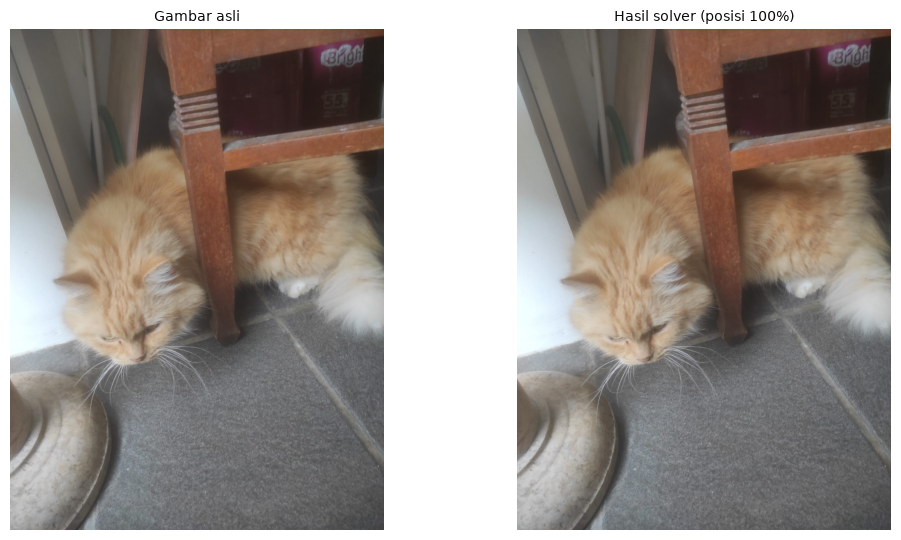

In [11]:
t = time.time()
res = solve_folder(OUT)
print(f"Selesai dalam {time.time() - t:.2f} detik")
report(res)
acc = evaluate(res, meta)
print(f"Akurasi posisi: {acc*100:.1f}%")

fig, ax = plt.subplots(1, 2, figsize=(11, 5.5))
solved = render(res)
show(ax[0], load_image(DEMO_IMAGE)[:solved.shape[0], :solved.shape[1]], "Gambar asli")
show(ax[1], solved, f"Hasil solver (posisi {acc*100:.0f}%)")
plt.tight_layout(); plt.show()

In [ ]:
RUN_GUI = True      # ubah ke False bila hanya ingin memuat kode tanpa membuka jendela


import queue
import threading
import traceback
import tkinter as tk
from tkinter import filedialog, messagebox

import customtkinter as ctk
from PIL import Image, ImageTk

ctk.set_appearance_mode("dark")
ctk.set_default_color_theme("blue")

CANVAS_BG = "#151515"
ACCENT, ACCENT_HOVER = "#2a78d6", "#1f62b3"
OK_GREEN, OK_HOVER = "#2e8b57", "#256f46"
GREEN_BGR, RED_BGR = (70, 200, 70), (60, 60, 235)        # warna sorot langkah (BGR)


def to_pil(bgr):
    return Image.fromarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))


def layout_preview(img, m, view_side=1000):
    """Gambar asli + bingkai berwarna + garis grid M x M, sesuai tata letak yang akan dipakai generator."""
    h, w = img.shape[:2]
    s = min(1.0, view_side / max(h, w))
    small = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else img.copy()
    try:
        b, ch, cw = plan_layout(h, w, m, BORDER)
    except ValueError as e:
        return small, f"Peringatan: {e}"
    x0 = y0 = int(round(b * s))
    x1, y1 = int(round((b + m * cw) * s)), int(round((b + m * ch) * s))
    tint = np.full_like(small, (230, 150, 40))                   # BGR -> biru
    out = cv2.addWeighted(small, 0.62, tint, 0.38, 0)
    out[y0:y1, x0:x1] = small[y0:y1, x0:x1]
    for i in range(1, m):
        xi, yi = x0 + int(round(i * cw * s)), y0 + int(round(i * ch * s))
        cv2.line(out, (xi, y0), (xi, y1), (255, 255, 255), 1, cv2.LINE_AA)
        cv2.line(out, (x0, yi), (x1, yi), (255, 255, 255), 1, cv2.LINE_AA)
    cv2.rectangle(out, (x0, y0), (x1 - 1, y1 - 1), (0, 0, 0), 2)
    return out, f"Bingkai {b}px · sel {cw}×{ch}px · {m * m} potongan"


def run_generate(img, m, out_dir):
    """Pekerjaan thread: buat bingkai + potongan, lalu siapkan gambar untuk tab Bingkai dan Potongan."""
    out = Path(out_dir)
    meta = generate(img, m, out, verbose=False)
    frame = cv2.imread(str(out / "frame.png"), cv2.IMREAD_UNCHANGED)
    pieces = [cv2.imread(str(out / p["file"])) for p in meta["pieces"]]
    return {"meta": meta, "frame_view": frame_on_checker(frame), "sheet_view": contact_sheet(pieces)}


def _accuracy(res, out_dir):
    """Akurasi posisi vs kunci jawaban jika metadata.json ada di folder; selain itu None."""
    mp = Path(out_dir) / "metadata.json"
    return evaluate(res, json.loads(mp.read_text(encoding="utf-8"))) if mp.exists() else None


def run_solve(out_dir, thr=THRESHOLD):
    """Pekerjaan thread: jalankan solver pada folder (bingkai + potongan), siapkan bahan animasi langkah."""
    t0 = time.time()
    res = solve_folder(out_dir)
    dt = time.time() - t0
    cv2.imwrite(str(Path(out_dir) / "solved.png"), render(res))

    m, (x0, y0, hw, hh) = res["m"], res["hole"]
    cw, ch = hw // m, hh // m
    base = np.clip(res["frame"], 0, 255).astype(np.uint8)
    base[y0:y0 + hh, x0:x0 + hw] = 32
    for i in range(1, m):
        cv2.line(base, (x0 + i * cw, y0), (x0 + i * cw, y0 + hh - 1), (70, 70, 70), 1)
        cv2.line(base, (x0, y0 + i * ch), (x0 + hw - 1, y0 + i * ch), (70, 70, 70), 1)
    phases = {}
    for ph, *_rest, b in res["steps"]:
        phases.setdefault(ph, []).append(percent(b))
    res.update({"base": base, "var_u8": [np.clip(v[2], 0, 255).astype(np.uint8) for v in res["variants"]],
                "acc": _accuracy(res, out_dir), "time": dt, "thr": thr, "phases": phases})
    return res


class App(ctk.CTk):
    VIEWS = ["Asli", "Bingkai", "Potongan", "Hasil solver"]

    def __init__(self):
        super().__init__()
        self.title("Puzzle World — Generator & Solver")
        self.geometry("1320x840")
        self.minsize(1100, 720)

        self.q = queue.Queue()
        self.src_name, self.src_path, self.src_array = None, None, None
        self._img_key, self._img_cache = None, None
        self.frame_view, self.sheet_view, self.res = None, None, None
        self.cur_step, self.playing, self.view = 0, False, "Asli"
        self._pil, self._tk, self._msg, self._jobs = None, None, "", {}

        self.grid_columnconfigure(1, weight=1)
        self.grid_rowconfigure(0, weight=1)
        self._build_sidebar()
        self._build_main()
        self.on_params()
        self.refresh()
        self.after(100, self._poll)
        self.protocol("WM_DELETE_WINDOW", self._on_close)

    # ------------------------------ susunan UI ------------------------------ #
    def _card(self, parent, title):
        card = ctk.CTkFrame(parent, corner_radius=12)
        card.pack(fill="x", padx=10, pady=(0, 10))
        ctk.CTkLabel(card, text=title, font=ctk.CTkFont(size=14, weight="bold"),
                     anchor="w").pack(fill="x", padx=14, pady=(12, 6))
        return card

    def _slider(self, card, frm, to, steps, init, cmd):
        lbl = ctk.CTkLabel(card, text="", anchor="w")
        lbl.pack(fill="x", padx=14)
        sl = ctk.CTkSlider(card, from_=frm, to=to, number_of_steps=steps, command=cmd)
        sl.set(init)
        sl.pack(fill="x", padx=14, pady=(0, 8))
        return lbl, sl

    def _build_sidebar(self):
        # kolom kiri: judul (tetap) + pengaturan (bisa di-scroll) + tombol aksi (tetap, selalu terlihat)
        left = ctk.CTkFrame(self, width=350, corner_radius=0)
        left.grid(row=0, column=0, sticky="nsew")
        left.grid_propagate(False)
        left.grid_columnconfigure(0, weight=1)
        left.grid_rowconfigure(1, weight=1)
        head = ctk.CTkFrame(left, fg_color="transparent")
        head.grid(row=0, column=0, sticky="ew")
        ctk.CTkLabel(head, text="Puzzle World", font=ctk.CTkFont(size=24, weight="bold"),
                     anchor="w").pack(fill="x", padx=14, pady=(14, 0))
        ctk.CTkLabel(head, text="Generator & Solver · Pengolahan Citra Digital", text_color="gray",
                     anchor="w").pack(fill="x", padx=14, pady=(0, 8))
        side = ctk.CTkScrollableFrame(left, corner_radius=0, fg_color="transparent")
        side.grid(row=1, column=0, sticky="nsew")

        bar = ctk.CTkFrame(left, corner_radius=0)
        bar.grid(row=2, column=0, sticky="ew")
        self.gen_btn = ctk.CTkButton(bar, text="Generate", height=40, font=ctk.CTkFont(size=14, weight="bold"),
                                     fg_color=ACCENT, hover_color=ACCENT_HOVER, command=self.do_generate)
        self.gen_btn.pack(fill="x", padx=14, pady=(12, 6))
        self.solve_btn = ctk.CTkButton(bar, text="Solve", height=40, font=ctk.CTkFont(size=14, weight="bold"),
                                       fg_color=OK_GREEN, hover_color=OK_HOVER, command=self.do_solve)
        self.solve_btn.pack(fill="x", padx=14, pady=(0, 12))

        # --- 1. gambar ---
        c1 = self._card(side, "1 · Gambar")
        ctk.CTkButton(c1, text="Pilih gambar…", command=self.choose_image).pack(fill="x", padx=14, pady=(0, 6))
        self.img_lbl = ctk.CTkLabel(c1, text="Belum ada gambar", text_color="gray", anchor="w",
                                    justify="left", wraplength=280)
        self.img_lbl.pack(fill="x", padx=14, pady=(0, 12))

        # --- 2. generator ---
        c2 = self._card(side, "2 · Generator")
        self.m_lbl, self.m_slider = self._slider(c2, 2, 12, 10, 4, self.on_params)
        ctk.CTkLabel(c2, text="Folder puzzle (keluaran generator / masukan solver)", anchor="w",
                     wraplength=290, justify="left").pack(fill="x", padx=14)
        row = ctk.CTkFrame(c2, fg_color="transparent")
        row.pack(fill="x", padx=14, pady=(0, 8))
        self.out_entry = ctk.CTkEntry(row)
        self.out_entry.insert(0, str(Path.cwd() / "puzzle_gui"))
        self.out_entry.pack(side="left", fill="x", expand=True)
        ctk.CTkButton(row, text="...", width=34, command=self.choose_out).pack(side="right", padx=(6, 0))
        ctk.CTkLabel(c2, text="", height=2).pack()

        ctk.CTkLabel(side, text="Solver hanya membaca frame.png dan piece_*.png. Jika ada metadata.json "
                                "(dibuat generator ini), akurasi ikut dihitung.", text_color="gray", anchor="w",
                     justify="left", wraplength=300).pack(fill="x", padx=14, pady=(0, 14))
        self.on_params()

    def _build_main(self):
        main = ctk.CTkFrame(self, fg_color="transparent")
        main.grid(row=0, column=1, sticky="nsew", padx=(4, 12), pady=12)
        main.grid_columnconfigure(0, weight=1)
        main.grid_rowconfigure(1, weight=1)

        head = ctk.CTkFrame(main, fg_color="transparent")
        head.grid(row=0, column=0, sticky="ew")
        head.grid_columnconfigure(1, weight=1)
        self.seg = ctk.CTkSegmentedButton(head, values=self.VIEWS, command=self.on_view)
        self.seg.set("Asli")
        self.seg.grid(row=0, column=0, sticky="w")
        self.info_lbl = ctk.CTkLabel(head, text="", anchor="w", text_color="gray")
        self.info_lbl.grid(row=0, column=1, sticky="ew", padx=14)
        self.progress = ctk.CTkProgressBar(head, mode="indeterminate", width=120)
        self.progress.grid(row=0, column=2, sticky="e")
        self.progress.grid_remove()

        self.canvas = tk.Canvas(main, bg=CANVAS_BG, highlightthickness=0)
        self.canvas.grid(row=1, column=0, sticky="nsew", pady=10)
        self.canvas.bind("<Configure>", lambda e: self._debounce("redraw", self.redraw, 40))

        self.step_frame = ctk.CTkFrame(main)
        self.step_frame.grid(row=2, column=0, sticky="ew", pady=(0, 10))
        self.step_frame.grid_columnconfigure(3, weight=1)
        ctk.CTkButton(self.step_frame, text="Mundur", width=70, command=lambda: self.set_step(self.cur_step - 1)).grid(
            row=0, column=0, padx=(10, 4), pady=10)
        self.play_btn = ctk.CTkButton(self.step_frame, text="Putar", width=80, command=self.toggle_play)
        self.play_btn.grid(row=0, column=1, padx=4)
        ctk.CTkButton(self.step_frame, text="Maju", width=64, command=lambda: self.set_step(self.cur_step + 1)).grid(
            row=0, column=2, padx=4)
        self.step_slider = ctk.CTkSlider(self.step_frame, from_=0, to=1, number_of_steps=1,
                                         command=lambda v: self.set_step(int(round(v))))
        self.step_slider.grid(row=0, column=3, sticky="ew", padx=10)
        ctk.CTkButton(self.step_frame, text="Akhir", width=56, command=lambda: self.set_step(10 ** 6)).grid(
            row=0, column=4, padx=4)
        ctk.CTkButton(self.step_frame, text="Simpan hasil…", width=110, fg_color="transparent", border_width=1,
                      command=self.save_result).grid(row=0, column=5, padx=(4, 10))
        self.step_frame.grid_remove()

        self.stat_lbl = ctk.CTkLabel(main, text="", anchor="w", justify="left", font=ctk.CTkFont(size=13, weight="bold"))
        self.stat_lbl.grid(row=3, column=0, sticky="ew", pady=(0, 6))
        self.log_box = ctk.CTkTextbox(main, height=130, state="disabled")
        self.log_box.grid(row=4, column=0, sticky="ew")
        self.log("Pilih gambar untuk memulai. Alur: Generate, lalu Solve.")

    # ------------------------------ utilitas -------------------------------- #
    def _debounce(self, key, fn, ms):
        if key in self._jobs:
            self.after_cancel(self._jobs[key])
        self._jobs[key] = self.after(ms, fn)

    def log(self, msg):
        self.log_box.configure(state="normal")
        self.log_box.insert("end", msg + "\n")
        self.log_box.see("end")
        self.log_box.configure(state="disabled")

    def set_busy(self, busy, text=""):
        for b in (self.gen_btn, self.solve_btn):
            b.configure(state="disabled" if busy else "normal")
        if busy:
            self.progress.grid()
            self.progress.start()
            self.info_lbl.configure(text=text)
        else:
            self.progress.stop()
            self.info_lbl.configure(text="")
            self.progress.grid_remove()

    def _params(self):
        return int(round(self.m_slider.get()))

    def on_params(self, *_):
        m = self._params()
        self.m_lbl.configure(text=f"Jumlah potongan M = {m}   ({m}×{m} = {m * m} potongan)")
        if self.view == "Asli" and hasattr(self, "canvas"):
            self._debounce("orig", self.show_original, 60)

    # ------------------------------- tampilan ------------------------------- #
    def on_view(self, value):
        self.view = value
        if value == "Hasil solver":
            self.step_frame.grid()
        else:
            self.step_frame.grid_remove()
            self.playing = False
            self.play_btn.configure(text="Putar")
        self.refresh()

    def refresh(self):
        v = self.view
        if v == "Asli":
            self.show_original()
        elif v == "Bingkai":
            self.info_lbl.configure(text="Bingkai = cincin tepi gambar; kotak-kotak = lubang transparan")
            self.show_array(self.frame_view, "Belum ada bingkai.\nKlik Generate.")
        elif v == "Potongan":
            self.info_lbl.configure(text="Potongan dalam urutan berkas (sudah diacak)" if self.sheet_view is not None else "")
            self.show_array(self.sheet_view, "Belum ada potongan.\nKlik Generate.")
        elif self.res is None:
            self.info_lbl.configure(text="")
            self.show_array(None, "Belum ada hasil.\nKlik Solve.")
        else:
            self.set_step(self.cur_step)

    def show_array(self, arr, msg=""):
        self._msg = msg
        self._pil = None if arr is None else to_pil(arr)
        self.redraw()

    def redraw(self):
        c = self.canvas
        cw, ch = c.winfo_width(), c.winfo_height()
        c.delete("all")
        if cw < 10 or ch < 10:
            return
        if self._pil is None:
            c.create_text(cw // 2, ch // 2, text=self._msg, fill="#8a8a8a", font=("Helvetica", 16), justify="center")
            return
        iw, ih = self._pil.size
        s = min(cw / iw, ch / ih)
        size = (max(1, int(iw * s)), max(1, int(ih * s)))
        self._tk = ImageTk.PhotoImage(self._pil.resize(size, Image.LANCZOS if s < 1 else Image.BILINEAR))
        c.create_image(cw // 2, ch // 2, image=self._tk)

    def effective_image(self):
        if self.src_array is None and self.src_path is None:
            return None
        key = self.src_name
        if self._img_key != key:
            self._img_cache = load_image(self.src_array if self.src_array is not None else self.src_path)
            self._img_key = key
        return self._img_cache

    def show_original(self):
        img = self.effective_image()
        if img is None:
            self.info_lbl.configure(text="")
            self.show_array(None, "Pilih gambar di panel kiri")
            return
        m = self._params()
        arr, info = layout_preview(img, m)
        self.info_lbl.configure(text=info)
        self.show_array(arr)

    # ---------------------------------- aksi -------------------------------- #
    def _set_source(self, name, path=None, array=None):
        try:
            self.src_name, self.src_path, self.src_array, self._img_key = name, path, array, None
            img = self.effective_image()
        except Exception as e:
            self.src_name = self.src_path = self.src_array = None
            messagebox.showerror("Gagal membuka gambar", str(e))
            return
        h, w = img.shape[:2]
        self.img_lbl.configure(text=f"{name}\n{w}×{h}px", text_color="white")
        self.log(f"Gambar dimuat: {name} ({w}×{h}px)")
        self.seg.set("Asli")
        self.on_view("Asli")

    def choose_image(self):
        path = filedialog.askopenfilename(title="Pilih gambar", filetypes=[
            ("Gambar", "*.png *.jpg *.jpeg *.bmp *.webp *.tif *.tiff"), ("Semua berkas", "*.*")])
        if path:
            self._set_source(Path(path).name, path=path)

    def choose_out(self):
        d = filedialog.askdirectory(title="Pilih folder puzzle")
        if d:
            self.out_entry.delete(0, "end")
            self.out_entry.insert(0, d)

    def do_generate(self):
        img = self.effective_image()
        if img is None:
            messagebox.showwarning("Belum ada gambar", "Pilih gambar dulu.")
            return
        out = self.out_entry.get().strip() or "puzzle_gui"
        m = self._params()
        self.playing = False
        self.set_busy(True, "Membuat bingkai dan potongan…")
        self.log(f"Generate: M={m}")
        self._spawn("gen", lambda: run_generate(img, m, out))

    def _check_folder(self):
        out = self.out_entry.get().strip() or "puzzle_gui"
        if not (Path(out) / "frame.png").exists() or not list(Path(out).glob("piece_*.png")):
            messagebox.showwarning("Puzzle belum ada", f"Folder '{out}' belum berisi frame.png dan piece_*.png.\n"
                                                      "Klik Generate dulu, atau pilih folder puzzle yang sudah ada.")
            return None
        return out

    def do_solve(self):
        out = self._check_folder()
        if out is None:
            return
        self.playing = False
        self.set_busy(True, "Solver bekerja…")
        self.log(f"Solve: ambang={THRESHOLD:.0f}%")
        self._spawn("solve", lambda: run_solve(out))

    def save_result(self):
        if self.res is None:
            messagebox.showinfo("Belum ada hasil", "Jalankan Solve dulu.")
            return
        path = filedialog.asksaveasfilename(title="Simpan hasil", defaultextension=".png",
                                            filetypes=[("PNG", "*.png"), ("JPEG", "*.jpg")], initialfile="hasil_puzzle.png")
        if path:
            ok, buf = cv2.imencode(Path(path).suffix or ".png", render(self.res))
            if ok:
                Path(path).write_bytes(buf.tobytes())
                self.log(f"Hasil disimpan: {path}")

    def _spawn(self, kind, fn):
        def work():
            try:
                self.q.put((kind, fn()))
            except Exception as e:
                self.q.put(("error", f"{e}\n\n{traceback.format_exc()}"))
        threading.Thread(target=work, daemon=True).start()

    def _poll(self):
        try:
            while True:
                kind, payload = self.q.get_nowait()
                self.set_busy(False)
                if kind == "gen":
                    self._on_generated(payload)
                elif kind == "solve":
                    self._on_solved(payload)
                else:
                    self.log("ERROR: " + payload.splitlines()[0])
                    messagebox.showerror("Terjadi kesalahan", payload.splitlines()[0])
        except queue.Empty:
            pass
        self.after(100, self._poll)

    def _on_generated(self, p):
        self.frame_view, self.sheet_view, self.res, self.cur_step = p["frame_view"], p["sheet_view"], None, 0
        meta = p["meta"]
        self.stat_lbl.configure(text="")
        self.log(f"Generate selesai: 1 bingkai + {meta['n_pieces']} potongan "
                 f"(bingkai {meta['border']}px, sel {meta['cell_size'][0]}×{meta['cell_size'][1]}px).")
        self.seg.set("Bingkai")
        self.on_view("Bingkai")

    def _on_solved(self, res):
        self.res = res
        n = len(res["steps"])
        self.step_slider.configure(from_=0, to=max(1, n), number_of_steps=max(1, n))
        parts = [f"{res['time']:.2f} dtk"]
        if res["acc"] is not None:
            parts.insert(0, f"akurasi posisi {res['acc'] * 100:.0f}%")
        self.stat_lbl.configure(text="  |  ".join(parts))
        for ph, label in ((1, "Tahap 1 (cocokkan ke bingkai)"), (2, "Tahap 2 (isi bagian dalam)")):
            sc = res["phases"].get(ph)
            if sc:
                self.log(f"{label}: {len(sc)} potongan, rata-rata {np.mean(sc):.1f}%, min {np.min(sc):.1f}%, "
                         f"ragu {sum(x < res['thr'] for x in sc)}")
        self.log("Hasil: " + "  |  ".join(parts) + "   (disimpan sebagai solved.png di folder puzzle)")
        self.seg.set("Hasil solver")
        self.on_view("Hasil solver")
        self.set_step(n)

    # ------------------------- animasi langkah solver ----------------------- #
    def set_step(self, k):
        if self.res is None:
            return
        res = self.res
        n = len(res["steps"])
        k = max(0, min(n, int(k)))
        self.cur_step = k
        self.step_slider.set(k)
        m = res["m"]
        x0, y0, hw, hh = res["hole"]
        cw, ch = hw // m, hh // m
        img = res["base"].copy()
        for (_, r, c, j, _b) in res["steps"][:k]:
            img[y0 + r * ch:y0 + (r + 1) * ch, x0 + c * cw:x0 + (c + 1) * cw] = res["var_u8"][j]
        if k > 0:
            phase, r, c, j, b = res["steps"][k - 1]
            pct = percent(b)
            ok = pct >= res["thr"]
            cv2.rectangle(img, (x0 + c * cw, y0 + r * ch), (x0 + (c + 1) * cw - 1, y0 + (r + 1) * ch - 1),
                          GREEN_BGR if ok else RED_BGR, max(2, min(cw, ch) // 30))
            i, _, _ = res["variants"][j]
            self.info_lbl.configure(text=f"Langkah {k}/{n} · Tahap {phase} · baris {r + 1}, kolom {c + 1} dari "
                                         f"{res['names'][i]} · {pct:.1f}% {'masuk' if ok else 'RAGU'}")
        else:
            self.info_lbl.configure(text=f"Langkah 0/{n} · lubang bingkai masih kosong")
        self.show_array(img)

    def toggle_play(self):
        if self.res is None:
            return
        if self.playing:
            self.playing = False
            self.play_btn.configure(text="Putar")
            return
        if self.cur_step >= len(self.res["steps"]):
            self.set_step(0)
        self.playing = True
        self.play_btn.configure(text="Jeda")
        self._tick()

    def _tick(self):
        if not self.playing or self.res is None:
            return
        n = len(self.res["steps"])
        if self.cur_step >= n:
            self.playing = False
            self.play_btn.configure(text="Putar")
            return
        self.set_step(self.cur_step + 1)
        self.after(max(40, min(250, 6000 // max(1, n))), self._tick)

    def _on_close(self):
        self.playing = False
        self.destroy()


if RUN_GUI:
    app = App()
    app.mainloop()